In [1]:

# CELL 1: Load invoice-level data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import gamma as gamma_dist
from scipy.stats import lognorm
from pathlib import Path

OUTPUT = Path("gamma_outputs")
OUTPUT.mkdir(exist_ok=True)

df = pd.read_csv("data/final_invoice_level.csv")

print("Dataset shape:", df.shape)
print(df[["InvoiceAmount"]].head())


Dataset shape: (36594, 13)
   InvoiceAmount
0         505.30
1         145.80
2         630.33
3         310.75
4        2286.24


**Importing Libraries and Loading the Dataset**  

The invoice-level dataset contains 36,594 observations, with each observation representing the total monetary value of a purchase invoice. This dataset forms the basis for modelling customer transaction amounts using the Gamma probability distribution. Invoice-level analysis ensures that complete purchase amounts are considered rather than individual product-line values.

In [2]:

# CELL 2: Prepare the Gamma variable

y = df["InvoiceAmount"].dropna()

# Gamma distribution requires positive observations
y = y[y > 0]

print("Number of observations:", len(y))
print("Minimum:", round(y.min(), 2))
print("Mean:", round(y.mean(), 2))
print("Median:", round(y.median(), 2))
print("Variance:", round(y.var(), 2))


Number of observations: 36594
Minimum: 0.38
Mean: 476.4
Median: 304.64
Variance: 1888534.36


**Selection and Descriptive Analysis of the Random Variable**

The analysis considers invoice amount as a positive continuous random variable. The mean transaction value is £476.40, while the median is £304.64, indicating a positively skewed distribution. The large variance of approximately 1,888,534.36 suggests substantial variability in customer spending, with some invoices having exceptionally high values. These characteristics motivate the investigation of the Gamma distribution.

In [3]:

# CELL 3: Gamma parameter estimation using MLE

shape, loc, scale = gamma_dist.fit(y, floc=0)

print("Gamma Parameters (MLE)")
print("----------------------")
print("Shape (alpha):", round(shape, 4))
print("Scale (theta):", round(scale, 4))
print("Location:", loc)

# Theoretical mean and variance
gamma_mean = shape * scale
gamma_variance = shape * (scale ** 2)

print("\nFitted Gamma Mean:", round(gamma_mean, 2))
print("Fitted Gamma Variance:", round(gamma_variance, 2))


Gamma Parameters (MLE)
----------------------
Shape (alpha): 1.0152
Scale (theta): 469.279
Location: 0

Fitted Gamma Mean: 476.4
Fitted Gamma Variance: 223563.02


**Gamma Parameter Estimation Using MLE**

Maximum Likelihood Estimation produced a shape parameter of approximately 1.0152 and a scale parameter of 469.2790. Since the shape parameter is close to 1, the fitted Gamma distribution resembles an Exponential distribution and exhibits substantial positive skewness. The theoretical mean of £476.40 agrees with the observed sample mean, whereas the theoretical variance of approximately 223,563 is considerably lower than the observed variance. This indicates that the fitted Gamma model may not adequately capture the extreme variability in transaction amounts.

In [4]:

# CELL 4: Method of Moments

mean = y.mean()
variance = y.var(ddof=0)

alpha_mom = (mean ** 2) / variance
theta_mom = variance / mean

print("Method of Moments")
print("-----------------")
print("Shape:", round(alpha_mom, 4))
print("Scale:", round(theta_mom, 4))

print("\nMaximum Likelihood Estimation")
print("-----------------------------")
print("Shape:", round(shape, 4))
print("Scale:", round(scale, 4))


Method of Moments
-----------------
Shape: 0.1202
Scale: 3964.0962

Maximum Likelihood Estimation
-----------------------------
Shape: 1.0152
Scale: 469.279


**Gamma Parameter Estimation Using Method of Moments**

The Method of Moments produced a shape parameter of approximately 0.1202 and a scale parameter of 3964.10, which differ substantially from the MLE estimates. This discrepancy arises because MOM directly incorporates the sample variance, which is strongly influenced by exceptionally large transaction amounts. The difference between the two estimation methods suggests that the Gamma distribution may struggle to represent both the central tendency and variability of the observed data simultaneously.


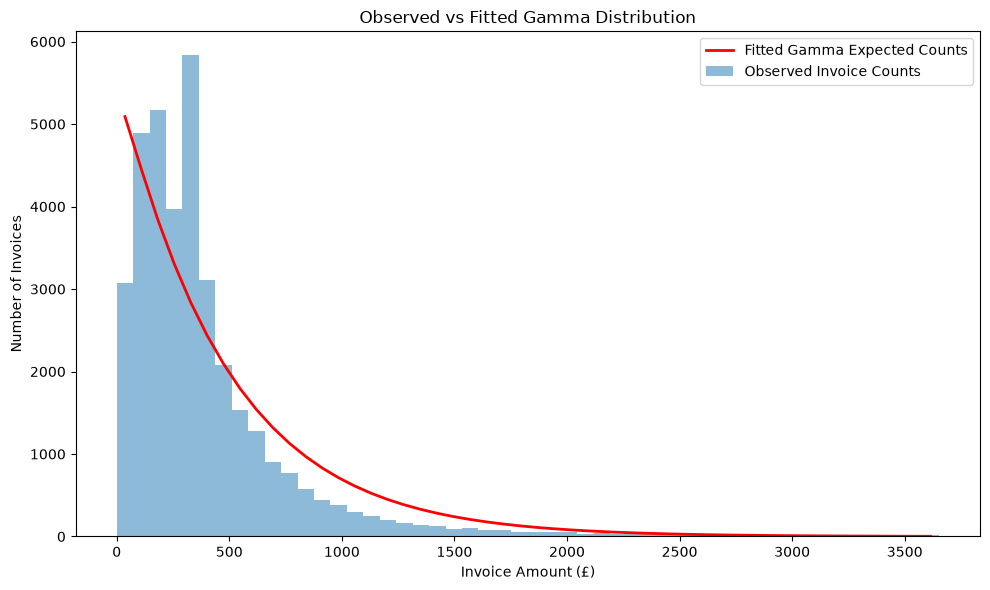

In [5]:

# CELL 5: Observed vs fitted Gamma distribution

upper = y.quantile(0.99)

bins = np.linspace(0, upper, 51)

observed, edges = np.histogram(y, bins=bins)

# Expected number in each bin under Gamma model
expected = len(y) * np.diff(
    gamma_dist.cdf(
        edges,
        a=shape,
        loc=loc,
        scale=scale
    )
)

midpoints = (edges[:-1] + edges[1:]) / 2

plt.figure(figsize=(10, 6))

plt.bar(
    edges[:-1],
    observed,
    width=np.diff(edges),
    align="edge",
    alpha=0.5,
    label="Observed Invoice Counts"
)

plt.plot(
    midpoints,
    expected,
    color="red",
    linewidth=2,
    label="Fitted Gamma Expected Counts"
)

plt.title("Observed vs Fitted Gamma Distribution")
plt.xlabel("Invoice Amount (£)")
plt.ylabel("Number of Invoices")

plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT / "gamma_fitted_distribution.png",
    dpi=300
)

plt.show()


**Observed vs Fitted Gamma Distribution**

The observed invoice frequencies are compared with the expected frequencies generated by the fitted Gamma distribution. Differences between the observed histogram and fitted model indicate areas where the theoretical distribution does not adequately represent actual customer spending behaviour. The distribution is highly right-skewed, and discrepancies between observed and expected frequencies suggest that the Gamma model may not fully capture the underlying spending pattern, particularly at higher transaction values.


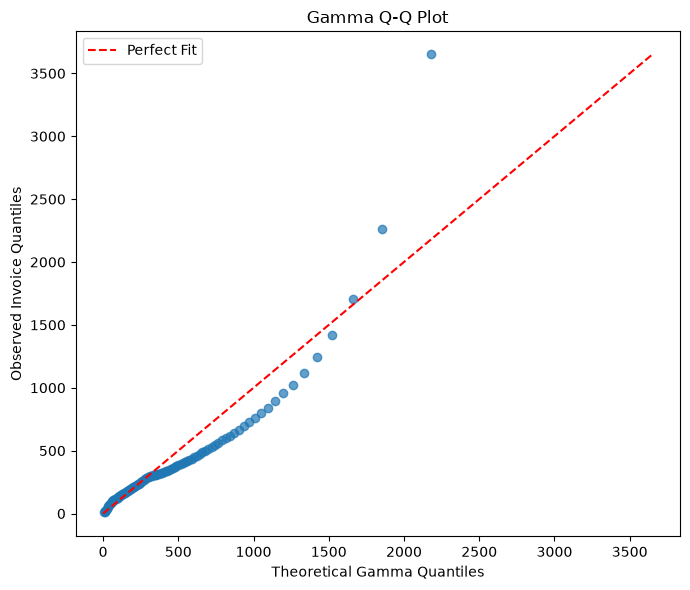

In [6]:

# CELL 6: Gamma Q-Q plot

probabilities = np.linspace(0.01, 0.99, 99)

theoretical = gamma_dist.ppf(
    probabilities,
    a=shape,
    loc=loc,
    scale=scale
)

observed = np.quantile(y, probabilities)

plt.figure(figsize=(7, 6))

plt.scatter(
    theoretical,
    observed,
    alpha=0.7
)

limit = max(theoretical.max(), observed.max())

plt.plot(
    [0, limit],
    [0, limit],
    "r--",
    label="Perfect Fit"
)

plt.title("Gamma Q-Q Plot")
plt.xlabel("Theoretical Gamma Quantiles")
plt.ylabel("Observed Invoice Quantiles")

plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT / "gamma_qq_plot.png",
    dpi=300
)

plt.show()


**Gamma Q-Q Plot**

The Gamma Q-Q plot compares the empirical quantiles of invoice amounts with the corresponding theoretical Gamma quantiles. Deviations from the 45-degree reference line indicate differences between the observed and fitted distributions. Particular attention is given to the upper quantiles, where large deviations would suggest that the Gamma model does not adequately represent high-value transactions. The plot therefore provides a visual assessment of the suitability of the Gamma distribution.

In [7]:

# CELL 7: AIC and BIC comparison

# Gamma log-likelihood
ll_gamma = gamma_dist.logpdf(
    y, a=shape, loc=loc, scale=scale
).sum()

# Two estimated parameters: shape and scale
k = 2
n = len(y)

gamma_aic = 2*k - 2*ll_gamma
gamma_bic = k*np.log(n) - 2*ll_gamma

# Fit Lognormal for comparison
ln_shape, ln_loc, ln_scale = lognorm.fit(
    y, floc=0
)

ll_lognorm = lognorm.logpdf(
    y, s=ln_shape,
    loc=ln_loc,
    scale=ln_scale
).sum()

lognorm_aic = 2*k - 2*ll_lognorm
lognorm_bic = k*np.log(n) - 2*ll_lognorm

results = pd.DataFrame({
    "Distribution": ["Gamma", "Lognormal"],
    "AIC": [gamma_aic, lognorm_aic],
    "BIC": [gamma_bic, lognorm_bic]
})

display(results.round(2))

results.to_csv(
    OUTPUT / "gamma_model_comparison.csv",
    index=False
)


,Distribution,AIC,BIC
0,Gamma,524482.28,524499.29
1,Lognormal,518591.05,518608.06


**Model Comparison Using AIC and BIC**

The Gamma distribution was compared with the Lognormal distribution using the Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC). The Gamma distribution produced AIC and BIC values of approximately **524482.28** and **524499.29**, respectively, whereas the Lognormal distribution produced lower values of approximately **518591.05** and **518608.06**. Since lower AIC and BIC values indicate a preferred model under these criteria, the Lognormal distribution provides a better relative fit to the observed invoice amounts. However, further goodness-of-fit evaluation is necessary to determine whether either distribution adequately represents the data.

In [8]:

# CELL 8: Probability calculation

threshold = 1000

# Probability predicted by fitted Gamma model
predicted_probability = gamma_dist.sf(
    threshold,
    a=shape,
    loc=loc,
    scale=scale
)

# Actual proportion observed in data
observed_probability = (y > threshold).mean()

print(
    "Gamma predicted probability:",
    round(predicted_probability, 4)
)

print(
    "Actual observed proportion:",
    round(observed_probability, 4)
)


Gamma predicted probability: 0.1218
Actual observed proportion: 0.0735


**Probability of Invoice Amount Exceeding £1,000**

Using the fitted Gamma distribution, the estimated probability of an invoice exceeding £1,000 is approximately **0.1218 (12.18%)**. However, the empirical proportion of invoices exceeding this threshold is approximately **0.0735 (7.35%)**. This indicates that the Gamma model overestimates the probability of transactions exceeding £1,000 by approximately 4.83 percentage points. The discrepancy demonstrates that the fitted model does not accurately capture the observed probability at this threshold and highlights the importance of evaluating theoretical probabilities against empirical observations.